# 07 · Experiment 6 — explanation quality, and the final system

**Research question (Exp. 6):** the brief wants the system to say *why*. Are the explanations our system produces **correct, useful and honest**?

**What an explanation contains.** For each clip: the verdict (REAL / FAKE / UNCERTAIN), a confidence level, the voice score and the face score with plain-language strength,
which modality looks manipulated, caveats (the two detectors disagree, the face crop is unreliable, the transcript is tiny) and the Whisper transcript for reference.
It is generated from the same two models that make the decision, so there is no separate "explainer network" that could disagree with the detector.

**How we measure quality** (every clip gets an honest out-of-fold prediction: 5-fold speaker-disjoint CV, as in Exp. 5):

| # | Test | Question | Why it is not circular |
|---|---|---|---|
| 1 | **Localization accuracy** | when the explanation says "voice / face / both / neither looks manipulated", does that match the dataset's ground truth for which stream was actually faked? | FakeAVCeleb labels each clip's real modality manipulation; the explanation never sees those labels |
| 2 | **Deletion test** | if we neutralize the stream the explanation blames, does the FAKE verdict disappear more often than when we neutralize the other stream? | checks that the highlighted evidence is what the decision depends on |
| 3 | **Caveat usefulness** | are clips that carry a caveat (detectors disagree, weak face crop) actually wrong more often? | an honest caveat must predict failure |

This notebook also trains the **final system** on all speakers (85% train / 15% validation for the C values, thresholds and UNCERTAIN band) and saves it as `final_system.joblib`, which the demo app loads.

**How to run on Kaggle:** add only `FakeAVCeleb-features`, accelerator None, Internet off, **Run All**.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp6")
os.makedirs(OUT, exist_ok=True)
SEED, K = 42, 5

## 1 · The verifier (single source of truth, also used by the demo app)
The next cell writes `verifier_core.py` so the notebook and the app run exactly the same code.

In [2]:
CORE_SRC = r'''"""Core of the multimodal deepfake verifier: train, score, decide (REAL / FAKE / UNCERTAIN) and explain.

Inputs are the frozen-encoder features used in Experiments 1-5:
  V : voice  = mean over the 13 wav2vec2-base layers of the time-averaged hidden states  (768,)
  F : face   = mean CLIP ViT-B/32 embedding of the face crops of 3 frames, re-normalised (512,)
No deep network is trained: two logistic regressions (one per stream) are averaged ("late mean").
"""
import numpy as np
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

CS = [1e-3, 1e-2, 1e-1, 1, 10]
ABSTAIN_TARGET = 0.15


def _best_threshold(yv, pv):
    grid = np.linspace(0.05, 0.95, 91)
    sc = np.array([balanced_accuracy_score(yv, (pv >= t).astype(int)) for t in grid])
    cand = grid[sc >= sc.max() - 1e-12]
    return float(cand[np.argmin(np.abs(cand - 0.5))])


def _fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        a = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or a > best[0]:
            best = (a, C, clf)
    return best[2], best[1]


class Verifier:
    STREAMS = ("voice", "face")

    # ------------------------------------------------------------------ training
    def fit(self, V, F, y, groups, tr=None, va=None, seed=42):
        """Train on speaker-disjoint train/val. If tr/va are not given, 15% of the speakers go to validation."""
        n = len(y)
        if tr is None:
            tr, va = next(GroupShuffleSplit(1, test_size=0.15, random_state=seed).split(np.arange(n), groups=groups))
        X = {"voice": V, "face": F}
        self.scaler, self.clf, self.C, self.stream_thr = {}, {}, {}, {}
        pva = {}
        for s in self.STREAMS:
            self.scaler[s] = StandardScaler().fit(X[s][tr])
            clf, C = _fit_lr(self.scaler[s].transform(X[s][tr]), y[tr], self.scaler[s].transform(X[s][va]), y[va])
            self.clf[s], self.C[s] = clf, C
            pva[s] = clf.predict_proba(self.scaler[s].transform(X[s][va]))[:, 1]
            self.stream_thr[s] = _best_threshold(y[va], pva[s])
        fused = (pva["voice"] + pva["face"]) / 2
        self.cutoff = _best_threshold(y[va], fused)
        self.band = float(np.quantile(np.abs(fused - self.cutoff), ABSTAIN_TARGET))   # UNCERTAIN half-width
        self.val_auc = float(roc_auc_score(y[va], fused))
        return self

    # ------------------------------------------------------------------ inference
    def stream_scores(self, V, F):
        X = {"voice": np.atleast_2d(V), "face": np.atleast_2d(F)}
        return {s: self.clf[s].predict_proba(self.scaler[s].transform(X[s]))[:, 1] for s in self.STREAMS}

    def score(self, V, F):
        p = self.stream_scores(V, F)
        return p["voice"], p["face"], (p["voice"] + p["face"]) / 2

    def decide(self, fused):
        """REAL / FAKE / UNCERTAIN from the fused score (UNCERTAIN = low confidence = close to the cut-off)."""
        fused = np.asarray(fused)
        d = np.abs(fused - self.cutoff)
        return np.where(d <= self.band, "UNCERTAIN", np.where(fused >= self.cutoff, "FAKE", "REAL"))

    # ------------------------------------------------------------------ explanation
    def explain(self, p_voice, p_face, face_rate=1.0, transcript=None):
        """Turn the scores of ONE clip into a structured, plain-language explanation."""
        p_voice, p_face = float(p_voice), float(p_face)
        fused = (p_voice + p_face) / 2
        verdict = str(self.decide(fused))
        dist = abs(fused - self.cutoff)
        confidence = "low" if verdict == "UNCERTAIN" else ("medium" if dist <= 2 * self.band else "high")

        def stream(name, p):
            thr = self.stream_thr[name]
            flag = p >= thr
            gap = p - thr
            strength = "strongly" if abs(gap) >= 0.3 else "moderately" if abs(gap) >= 0.12 else "weakly"
            return dict(name=name, score=round(p, 3), threshold=round(thr, 3), flags_fake=bool(flag),
                        gap=round(gap, 3), strength=strength)

        sv, sf = stream("voice", p_voice), stream("face", p_face)
        v, f = sv["flags_fake"], sf["flags_fake"]
        pattern = ("both the voice and the face look manipulated" if v and f else
                   "the voice looks synthetic or cloned while the face looks genuine" if v else
                   "the face looks swapped or generated while the voice looks genuine" if f else
                   "neither the voice nor the face shows clear signs of manipulation")
        suspected = "both" if v and f else "voice" if v else "face" if f else "none"
        driver = max((sv, sf), key=lambda s: s["gap"])["name"] if verdict == "FAKE" else \
                 min((sv, sf), key=lambda s: s["gap"])["name"] if verdict == "REAL" else None

        caveats = []
        if verdict == "UNCERTAIN":
            caveats.append("the combined score is too close to the decision boundary to call either way")
        if v != f:
            caveats.append("the voice and face detectors disagree, so the decision rests on averaging two opposing signals")
        if face_rate < 0.67:
            caveats.append(f"a face was located in only {round(face_rate * 3)} of 3 sampled frames, so the face evidence is less reliable")
        if transcript is not None and len(str(transcript).split()) <= 3:
            caveats.append("the speech transcript is very short, so little speech was available")

        head = {"FAKE": "Verdict: FAKE", "REAL": "Verdict: REAL", "UNCERTAIN": "Verdict: UNCERTAIN"}[verdict]
        lines = [f"{head} (confidence: {confidence}; fused score {fused:.2f}, cut-off {self.cutoff:.2f})."]
        lines.append(f"Evidence: {pattern}.")
        for s in (sv, sf):
            lines.append(f"- {s['name'].capitalize()} model: score {s['score']:.2f} vs its threshold {s['threshold']:.2f}, "
                         f"{s['strength']} {'towards fake' if s['flags_fake'] else 'towards real'}.")
        if caveats:
            lines.append("Caveats: " + "; ".join(caveats) + ".")
        if transcript:
            lines.append(f'Words spoken (ASR, not used in the score): "{str(transcript).strip()}"')
        return dict(verdict=verdict, confidence=confidence, fused=round(fused, 3), cutoff=round(self.cutoff, 3),
                    band=round(self.band, 3), voice=sv, face=sf, suspected=suspected, driver=driver,
                    caveats=caveats, text="\n".join(lines))

    # ------------------------------------------------------------------ persistence
    def save(self, path):
        joblib.dump(self, path)

    @staticmethod
    def load(path):
        return joblib.load(path)
'''
open(f"{OUT}/verifier_core.py", "w").write(CORE_SRC)
import sys; sys.path.insert(0, OUT)
from verifier_core import Verifier

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Add the FakeAVCeleb-features dataset as an input.")

Z = np.load(find("features.npz"))
meta = pd.read_csv(find("meta.csv")).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all()
keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
meta = meta[keep].reset_index(drop=True)
V, F = Z["audio_layers"][keep].mean(1), Z["image"][keep]
y, groups, cats = meta.label.values, meta.speaker.values, meta.category.values
audio_fake = np.isin(cats, ["RVFA", "FVFA"]); video_fake = np.isin(cats, ["FVRA", "FVFA"])
transcript = meta.transcript.fillna("").astype(str).values if "transcript" in meta.columns else np.array([""] * len(y))
face_rate = meta.face_rate.values if "face_rate" in meta.columns else np.ones(len(y))
print("clips:", len(y), meta.category.value_counts().to_dict())

clips: 998 {'RVRA': 500, 'FVRA': 166, 'RVFA': 166, 'FVFA': 166}


## 2 · Out-of-fold explanations for every clip

In [3]:
n = len(y)
order = np.random.RandomState(SEED).permutation(len(np.unique(groups)))
gk = np.array([dict(zip(np.unique(groups), order))[g] for g in groups])
rows, models = [None] * n, {}
for k, (trv, te) in enumerate(GroupKFold(K).split(np.arange(n), groups=gk)):
    a, b = next(GroupShuffleSplit(1, test_size=0.15, random_state=SEED + k).split(trv, groups=groups[trv]))
    m = Verifier().fit(V, F, y, groups, tr=trv[a], va=trv[b])
    models[k] = m
    pv, pf, pm = m.score(V[te], F[te])
    for j, i in enumerate(te):
        e = m.explain(pv[j], pf[j], face_rate[i], transcript[i])
        e.update(i=i, fold=k)
        rows[i] = e
print("fold models trained:", len(models))

df = pd.DataFrame(dict(
    clip_id=meta.clip_id.values, category=cats, label=y, speaker=groups, fold=[r["fold"] for r in rows],
    verdict=[r["verdict"] for r in rows], confidence=[r["confidence"] for r in rows], fused=[r["fused"] for r in rows],
    p_voice=[r["voice"]["score"] for r in rows], p_face=[r["face"]["score"] for r in rows],
    voice_flag=[r["voice"]["flags_fake"] for r in rows], face_flag=[r["face"]["flags_fake"] for r in rows],
    suspected=[r["suspected"] for r in rows], driver=[r["driver"] for r in rows],
    caveats=["; ".join(r["caveats"]) for r in rows], face_rate=face_rate, explanation=[r["text"] for r in rows]))
df["correct"] = ((df.verdict == "FAKE") & (df.label == 1)) | ((df.verdict == "REAL") & (df.label == 0))
df.to_csv(f"{OUT}/exp6_explanations_all.csv", index=False)
u = df.verdict == "UNCERTAIN"
print(f"verdicts: {df.verdict.value_counts().to_dict()} | accuracy on answered {df.correct[~u].mean():.3f}")
print("\nExample explanation (a face-fake):\n" + df[df.category == "FVRA"].explanation.iloc[0])

fold models trained: 5
verdicts: {'REAL': 447, 'FAKE': 401, 'UNCERTAIN': 150} | accuracy on answered 0.849

Example explanation (a face-fake):
Verdict: REAL (confidence: high; fused score 0.36, cut-off 0.59).
Evidence: the face looks swapped or generated while the voice looks genuine.
- Voice model: score 0.08 vs its threshold 0.83, strongly towards real.
- Face model: score 0.63 vs its threshold 0.50, moderately towards fake.
Caveats: the voice and face detectors disagree, so the decision rests on averaging two opposing signals.
Words spoken (ASR, not used in the score): "watch it anyway but not being in is quite an ask because you don't know what's going on yeah so actually it was a surprise to Oscar"


## 3 · Test 1 — does "which stream looks manipulated" match the truth?
Per-stream: the voice flag against the true audio label, the face flag against the true video label. Then the exact four-way pattern.

In [4]:
res = []
for name, flag, truth in (("voice flag vs audio_fake", df.voice_flag.values, audio_fake), ("face flag vs video_fake", df.face_flag.values, video_fake)):
    res.append(dict(test=name, accuracy=(flag == truth).mean(), recall_of_fakes=flag[truth].mean(), false_alarm_rate=flag[~truth].mean()))
truth_pat = np.where(audio_fake & video_fake, "both", np.where(audio_fake, "voice", np.where(video_fake, "face", "none")))
res.append(dict(test="exact pattern (none / voice / face / both)", accuracy=(df.suspected.values == truth_pat).mean(), recall_of_fakes=np.nan, false_alarm_rate=np.nan))
loc = pd.DataFrame(res).round(3); display(loc); loc.to_csv(f"{OUT}/exp6_T1_localization.csv", index=False)
cm = pd.crosstab(pd.Series(truth_pat, name="truth"), pd.Series(df.suspected.values, name="explanation says"))
cm = cm.reindex(index=["none", "voice", "face", "both"], columns=["none", "voice", "face", "both"], fill_value=0)
display(cm); cm.to_csv(f"{OUT}/exp6_T1_pattern_confusion.csv")
ans = (df.verdict == "FAKE") & (df.label == 1)
print(f"\nAmong correctly flagged FAKE clips ({ans.sum()}): exact manipulated-stream match = {(df.suspected.values == truth_pat)[ans].mean():.3f}")
print("by true type:", {c: round(float((df.suspected.values == truth_pat)[ans & (cats == c)].mean()), 3) for c in ("RVFA", "FVRA", "FVFA")})

,test,accuracy,recall_of_fakes,false_alarm_rate
0,voice flag vs audio_fake,0.905,0.973,0.129
1,face flag vs video_fake,0.779,0.798,0.231
2,exact pattern (none / voice / face / both),0.704,NaN,NaN


explanation says,none,voice,face,both
truth,,,,
none,333,50,105,12
voice,3,126,0,37
face,36,7,106,17
both,2,22,4,138



Among correctly flagged FAKE clips (349): exact manipulated-stream match = 0.754
by true type: {'RVFA': 0.73, 'FVRA': 0.5, 'FVFA': 0.852}


## 4 · Test 2 — deletion test
For clips the system calls FAKE, neutralize one stream (its score is set to its own threshold, i.e. "no opinion") and recompute the fused score with that fold's model.
The **blamed** stream is the one with the larger gap above its threshold. If the explanation is faithful, neutralizing the blamed stream should remove the FAKE verdict more often than neutralizing the other one.

In [5]:
flip = []
for i in np.where(df.verdict == "FAKE")[0]:
    m = models[df.fold[i]]
    pv, pf = df.p_voice[i], df.p_face[i]
    tv, tf = m.stream_thr["voice"], m.stream_thr["face"]
    blamed = "voice" if (pv - tv) >= (pf - tf) else "face"
    out = {}
    for nm, (a, b) in {"voice": (tv, pf), "face": (pv, tf)}.items():
        out[nm] = str(m.decide((a + b) / 2)) != "FAKE"
    other = "face" if blamed == "voice" else "voice"
    flip.append(dict(i=i, category=cats[i], blamed=blamed, flips_if_blamed_removed=out[blamed], flips_if_other_removed=out[other]))
fl = pd.DataFrame(flip)
dt = pd.DataFrame([dict(group="all FAKE verdicts", n=len(fl), verdict_lost_when_BLAMED_stream_removed=fl.flips_if_blamed_removed.mean(),
                        verdict_lost_when_OTHER_stream_removed=fl.flips_if_other_removed.mean())]
                  + [dict(group=f"true type {c}", n=int((fl.category == c).sum()),
                          verdict_lost_when_BLAMED_stream_removed=fl[fl.category == c].flips_if_blamed_removed.mean(),
                          verdict_lost_when_OTHER_stream_removed=fl[fl.category == c].flips_if_other_removed.mean()) for c in ("RVFA", "FVRA", "FVFA")]).round(3)
display(dt); dt.to_csv(f"{OUT}/exp6_T2_deletion.csv", index=False)

,group,n,verdict_lost_when_BLAMED_stream_removed,verdict_lost_when_OTHER_stream_removed
0,all FAKE verdicts,401,0.289,0.0
1,true type RVFA,137,0.482,0.0
2,true type FVRA,50,0.400,0.0
3,true type FVFA,162,0.068,0.0


## 5 · Test 3 — do the caveats predict errors?

In [6]:
ans_df = df[df.verdict != "UNCERTAIN"].copy()
ans_df["disagree"] = ans_df.voice_flag != ans_df.face_flag
ans_df["weak_face"] = ans_df.face_rate < 0.67
rows3 = []
for col in ("disagree", "weak_face"):
    for val in (False, True):
        s = ans_df[ans_df[col] == val]
        rows3.append(dict(caveat=col, present=val, answered_clips=len(s), accuracy=s.correct.mean() if len(s) else np.nan))
rows3.append(dict(caveat="confidence level (answered clips)", present="high", answered_clips=int((ans_df.confidence == "high").sum()), accuracy=ans_df[ans_df.confidence == "high"].correct.mean()))
rows3.append(dict(caveat="confidence level (answered clips)", present="medium", answered_clips=int((ans_df.confidence == "medium").sum()), accuracy=ans_df[ans_df.confidence == "medium"].correct.mean()))
cv = pd.DataFrame(rows3).round(3); display(cv); cv.to_csv(f"{OUT}/exp6_T3_caveats.csv", index=False)

,caveat,present,answered_clips,accuracy
0,disagree,False,548,0.914
1,disagree,True,300,0.730
2,weak_face,False,638,0.857
3,weak_face,True,210,0.824
4,confidence level (answered clips),high,675,0.881
5,confidence level (answered clips),medium,173,0.723


## 7 · Figure

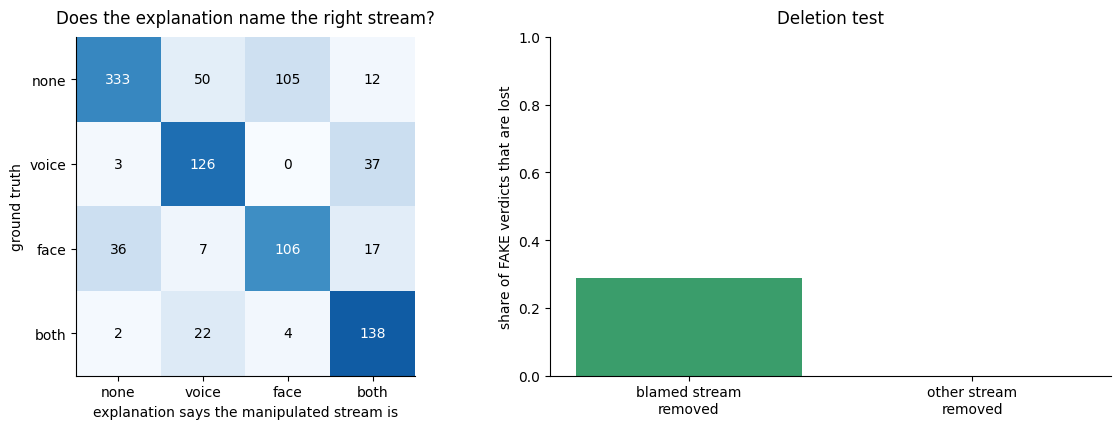

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
im = ax[0].imshow(cm.values / cm.values.sum(1, keepdims=True).clip(1), cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(cm.columns); ax[0].set_yticks(range(4)); ax[0].set_yticklabels(cm.index)
for i in range(4):
    for j in range(4):
        ax[0].text(j, i, int(cm.values[i, j]), ha="center", va="center", color="white" if cm.values[i, j] / max(cm.values[i].sum(), 1) > .5 else "black", fontsize=10)
ax[0].set_xlabel("explanation says the manipulated stream is"); ax[0].set_ylabel("ground truth")
ax[0].set_title("Does the explanation name the right stream?", pad=10)
ax[1].bar(["blamed stream\nremoved", "other stream\nremoved"], [fl.flips_if_blamed_removed.mean(), fl.flips_if_other_removed.mean()], color=["#3a9d6b", "#999"])
ax[1].set_ylim(0, 1); ax[1].set_ylabel("share of FAKE verdicts that are lost")
ax[1].set_title("Deletion test", pad=10)
for x in ax: x.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/exp6_explanation_quality.png", dpi=150); plt.show()

## 8 · Train and save the final system
Same recipe as the folds, but on all speakers (15% of speakers held out only to choose C, the thresholds and the UNCERTAIN band).

In [9]:
final = Verifier().fit(V, F, y, groups, seed=SEED)
final.save(f"{OUT}/final_system.joblib")
print(f"saved final_system.joblib | cut-off {final.cutoff:.2f} | UNCERTAIN half-width {final.band:.3f} | stream thresholds {final.stream_thr} | validation AUC {final.val_auc:.3f}")
print(sorted(os.listdir(OUT)))

saved final_system.joblib | cut-off 0.43 | UNCERTAIN half-width 0.041 | stream thresholds {'voice': 0.6, 'face': 0.58} | validation AUC 0.955
['__pycache__', 'exp6_T1_localization.csv', 'exp6_T1_pattern_confusion.csv', 'exp6_T2_deletion.csv', 'exp6_T3_caveats.csv', 'exp6_T4_human_rating_sheet.csv', 'exp6_explanation_quality.png', 'exp6_explanations_all.csv', 'final_system.joblib', 'verifier_core.py']
